# Buổi A4: Chia sổ thành tập học và tập thi

**Hiện trường.** Một kỹ sư đến khoa, giới thiệu "cậu Tí 2.0" và báo cáo: *"Máy mới đoán chính xác tuyệt đối trên 442 bệnh án. Sai lệch bằng 0."* Chị Hạnh nhớ lại bài học ở A2: **điểm quá đẹp là dấu hiệu cảnh báo**. Chị hỏi lại một câu đơn giản: *"Anh chấm máy bằng những bệnh nhân nào?"* Kỹ sư im lặng: máy được chấm trên chính những bệnh án nó đã đọc.

Giống như cho học sinh thi lại **đúng đề đã làm**: ai thuộc lòng đáp án cũng được điểm tuyệt đối, mà chưa chắc đã hiểu bài.

**Câu hỏi của buổi này:** *làm sao chấm một cỗ máy sao cho điểm của nó phản ánh đúng khả năng đoán những ca chưa từng gặp?*

**Mindset của người làm dữ liệu:** điểm trên dữ liệu đã học là *lời tự khai* của máy. Điểm trên dữ liệu chưa từng thấy mới là *lời khai trước tòa*.

**Chuẩn bị:** không cần tải file. Cú pháp đã học ở A1 đến A3 sẽ không giải thích lại.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Chấm máy trên đúng sổ nó đã học: kết quả có tin được không? |
| Chặng 1 | Chia sổ thành hai phần: `train_test_split` |
| Chặng 2 | Chấm lại công bằng: ai thật sự giỏi? |
| Chặng 3 | Hạt giống và tỉ lệ chia: điểm thi có đổi theo cách chia không? |
| Chặng 4 | Nhìn trộm tập thi: cách tự lừa mình phổ biến nhất |

## Chặng 0: Chấm máy trên đúng sổ nó đã học

**Câu hỏi:** hai cỗ máy (cậu Tí cũ và cậu Tí 2.0) được chấm trên 442 bệnh án đã đọc. Ai tốt hơn?

Cậu Tí cũ là hồi quy tuyến tính quen thuộc. Cậu Tí 2.0 là một **cây quyết định**: nó hỏi một chuỗi câu hỏi có/không về các cột (kiểu "BMI trên 27 chưa? huyết áp trên 100 chưa?") để chia bệnh nhân thành các nhóm nhỏ. Nếu ta không giới hạn số câu hỏi, cây cứ hỏi tiếp cho đến khi mỗi nhóm chỉ còn **một người**. Nghe có vẻ gì đó quen: cậu ta đang *học thuộc lòng*.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
original = load_diabetes(as_frame=True, scaled=False).frame
X = original.drop(columns="target")
y = original["target"]

**Giải thích từng dòng**

- `from sklearn.datasets import load_diabetes`: (đã học) hàm mở bộ dữ liệu.
- `from sklearn.linear_model import LinearRegression`: (đã học) hồi quy tuyến tính, cậu Tí cũ.
- `from sklearn.tree import DecisionTreeRegressor`: lấy cỗ máy mới: `DecisionTreeRegressor`, **cây quyết định dùng để đoán một con số** (Regressor là loại đoán số; ta sẽ học kỹ ở phần C).
- `original = load_diabetes(as_frame=True, scaled=False).frame`: (đã học ở A2) nạp bản sổ gốc.
- `X = original.drop(columns="target")`: (đã học ở A2) bảng đề bài gồm 10 cột.
- `y = original["target"]`: (đã học ở A2) cột đáp án.

In [3]:
def miss(model, X, y):
    return (y - model.predict(X)).abs().mean()

linear = LinearRegression().fit(X, y)
memorizer = DecisionTreeRegressor(random_state=0).fit(X, y)
print(f"Linear     : average miss {miss(linear, X, y):.1f}")
print(f"Memorizer  : average miss {miss(memorizer, X, y):.1f}")

Linear     : average miss 43.3
Memorizer  : average miss 0.0


**Giải thích từng dòng**

- `def miss(model, X, y): ...`: (đã học ở A2) chức năng tính sai lệch trung bình, định nghĩa lại vì đây là notebook mới.
- `linear = LinearRegression().fit(X, y)`: (đã học) cho máy tuyến tính học **toàn bộ** sổ.
- `memorizer = DecisionTreeRegressor(random_state=0).fit(X, y)`: tạo cây quyết định (không giới hạn độ sâu, mặc định) và cho học toàn bộ sổ. `random_state=0` là hạt giống của cây: khi hai câu hỏi tốt ngang nhau, cây phải chọn một, và hạt giống quyết định lần nào cũng chọn giống nhau. Cũng giống hạt giống ở A2.
- `print(f"... {miss(linear, X, y):.1f}")`: in sai lệch của từng máy.

**Cách đọc**

- **Con số:** máy tuyến tính lệch khoảng 43 điểm, còn cây quyết định lệch **0,0**.
- **Bức tranh:** cậu Tí 2.0 trông như thiên tài: không sai một ca nào. Nhưng nhớ A2: *điểm hoàn hảo là dấu hiệu cảnh báo*. Cây đã hỏi đến khi mỗi bệnh nhân nằm riêng một ngăn, rồi ghi nhớ điểm của người đó. Hỏi lại ca đã thuộc thì đúng hết, đó không phải "hiểu".
- **Câu hỏi tiếp:** làm sao biết cậu ta thật sự giỏi hay chỉ thuộc lòng? Ta cần **ca chưa từng thấy**.

**Mang về chặng 0:** chấm máy bằng chính dữ liệu nó đã học chỉ cho ta thấy khả năng *thuộc lòng*, không thấy khả năng *hiểu*.

## Chặng 1: Chia sổ thành hai phần

**Câu hỏi:** ta lấy đâu ra những ca "chưa từng thấy" khi tất cả bệnh án đều đã có trong tay?

Mẹo: **giấu đi một phần** của cuốn sổ. Cho máy học phần còn lại (**tập học**, train), rồi chấm máy bằng phần đã giấu (**tập thi**, test). Với máy, đó là những bệnh nhân hoàn toàn mới, nhưng ta vẫn biết đáp án để chấm điểm.

In [4]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(353, 10) (89, 10)


**Giải thích từng dòng**

- `from sklearn.model_selection import train_test_split`: lấy hàm chia sổ từ module `model_selection` (module chuyên về **chọn và đánh giá mô hình** của sklearn).
- `X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)`: chia bảng đề `X` và cột đáp án `y` **cùng một cách** (dòng nào vào tập thi thì cả đề lẫn đáp án của dòng đó vào tập thi). Hàm trả về **bốn thứ** theo đúng thứ tự: đề học, đề thi, đáp án học, đáp án thi; ta gán bốn tên cùng lúc.
- `test_size=0.2`: **tỉ lệ dành cho tập thi**: 0,2 nghĩa là 20% (khoảng 89 người) vào tập thi, 80% (khoảng 353 người) vào tập học. 20% đến 30% là mức hay dùng.
- `random_state=42`: **hạt giống của phép xáo trộn**. Hàm xáo trộn sổ ngẫu nhiên trước khi cắt, để tập thi không chỉ toàn người ở cuối sổ. Hạt giống là *bộ số cố định*: ai chạy với `42` cũng ra đúng cùng cách chia, đi đâu dùng cũng được. Số 42 chỉ là thói quen của dân làm dữ liệu, số nào cũng được. Không đặt thì mỗi lần chạy ra một cách chia khác.
- `print(X_train.shape, X_test.shape)`: (đã học `shape` ở A2) kiểm tra: tập học (353, 10), tập thi (89, 10).

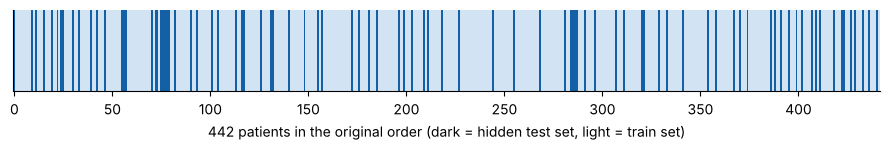

In [5]:
# Decorative diagram: just run it, no need to read the code line by line.
is_test = np.isin(np.arange(len(X)), X_test.index)
strip = is_test.astype(int)[None, :]
fig, ax = plt.subplots(figsize=(9, 1.6))
ax.imshow(strip, aspect="auto", cmap="Blues", vmin=-0.3, vmax=1.3, interpolation="nearest")
ax.set_yticks([]); ax.set_xlabel("442 patients in the original order (dark = hidden test set, light = train set)")
plt.tight_layout(); plt.show()

**Cách đọc**

- **Con số:** khoảng 89 ô sẫm (tập thi) rải khắp 442 vị trí.
- **Bức tranh:** những người bị giấu không dồn vào đầu hay cuối cuốn sổ mà rải **ngẫu nhiên** khắp nơi. Nếu cuốn sổ xếp theo thời gian hay theo bệnh viện mà ta chỉ cắt 20% cuối, tập thi sẽ khác hẳn tập học, và điểm sẽ không công bằng. Xáo trộn trước khi cắt là cách chống chuyện đó.
- **Một điều chưa bàn đến:** nếu dữ liệu có yếu tố thời gian (ví dụ giá cổ phiếu), việc xáo trộn là sai vì máy sẽ "nhìn thấy tương lai". Phần nâng cao sẽ nói kỹ, ở đây dữ liệu bệnh nhân không có thứ tự thời gian.

**Mang về chặng 1:** `train_test_split` giấu một phần sổ làm tập thi. Bốn đầu ra: đề học, đề thi, đáp án học, đáp án thi. `test_size` là tỉ lệ giấu, `random_state` là hạt giống để cách chia lặp lại được.

## Chặng 2: Chấm lại công bằng

**Câu hỏi:** khi chỉ được học trên tập học, rồi bị hỏi những ca chưa từng thấy, ai giỏi thật?

In [6]:
linear = LinearRegression().fit(X_train, y_train)
memorizer = DecisionTreeRegressor(random_state=0).fit(X_train, y_train)
names = ["Guess the average", "Linear", "Memorizer (tree)"]
train_err = [(y_train - y_train.mean()).abs().mean(), miss(linear, X_train, y_train), miss(memorizer, X_train, y_train)]
test_err = [(y_test - y_train.mean()).abs().mean(), miss(linear, X_test, y_test), miss(memorizer, X_test, y_test)]

**Giải thích từng dòng**

- `linear = LinearRegression().fit(X_train, y_train)`: học lại **chỉ trên tập học**. Tập thi hoàn toàn bị giấu.
- `memorizer = DecisionTreeRegressor(random_state=0).fit(X_train, y_train)`: tương tự cho cây quyết định.
- `names = ["Guess the average", "Linear", "Memorizer (tree)"]`: tên ba người chơi, gồm cả "mốc lười" đoán trung bình.
- `train_err = [(y_train - y_train.mean()).abs().mean(), ...]`: sai lệch trên **tập học** của ba người chơi. Với mốc lười, ta dùng trung bình của tập học để đoán.
- `test_err = [(y_test - y_train.mean()).abs().mean(), ...]`: sai lệch trên **tập thi**. Chú ý mốc lười vẫn dùng trung bình của **tập học** (không được nhìn trộm trung bình của tập thi, vì ngoài đời ta chưa biết đáp án của ca mới).

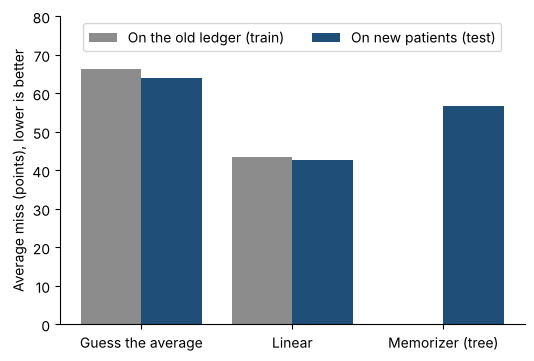

In [7]:
pos = np.arange(len(names))
plt.bar(pos - 0.2, train_err, width=0.4, color=GRAY, label="On the old ledger (train)")
plt.bar(pos + 0.2, test_err, width=0.4, color=BLUE, label="On new patients (test)")
plt.xticks(pos, names)
plt.ylabel("Average miss (points), lower is better")
plt.ylim(0, 80)
plt.legend(loc="upper center", ncol=2); plt.show()

**Giải thích từng dòng**

- `pos = np.arange(len(names))`: `np.arange(3)` tạo dãy `0, 1, 2`: vị trí của ba cụm cột trên trục ngang.
- `plt.bar(pos - 0.2, train_err, width=0.4, color=GRAY, label="...")`: vẽ cột sai lệch trên tập học, **dịch sang trái** 0,2 so với vị trí chuẩn; `width=0.4` là độ rộng cột. Dịch trái và phải để hai cột đứng cạnh nhau thay vì chồng lên nhau.
- `plt.bar(pos + 0.2, test_err, width=0.4, color=BLUE, label="...")`: cột tập thi, dịch sang phải 0,2.
- `plt.xticks(pos, names)`: gắn tên người chơi lên trục ngang tại các vị trí chuẩn.
- `plt.ylim(0, 80)`: `plt.ylim` đặt khoảng hiển thị của trục dọc (đã học `set_ylim` ở A3): chừa khoảng trống phía trên cho chú giải.
- `plt.legend(loc="upper center", ncol=2); plt.show()`: hiện chú giải đặt ở **giữa phía trên** (`loc`) và xếp thành 2 cột (`ncol=2`) để không che cột nào, rồi hiện hình.

**Cách đọc**

- **Con số:** cây quyết định lệch **0,0** trên sổ cũ nhưng khoảng **57** trên bệnh nhân mới. Máy tuyến tính lệch khoảng 43 ở cả hai nơi. Mốc lười lệch khoảng 64.
- **Bức tranh:** cột xanh đậm cao hơn cột xám ở cây quyết định rất nhiều: đó là khoảng cách giữa *thuộc lòng* và *hiểu bài*. Cậu Tí 2.0 không những không giỏi hơn, mà còn **tệ hơn cậu Tí cũ** khi gặp ca lạ, chỉ hơn mốc lười không đáng kể. Máy tuyến tính thì điểm hai nơi gần như nhau: nó chưa học vẹt nên điểm trên sổ cũ phản ánh đúng khả năng thật.
- **Tên gọi:** hiện tượng học thuộc đến mức không tổng quát hóa được gọi là **quá khớp** (overfitting). Ta sẽ gặp lại ở nhiều buổi, đặc biệt B5.

Giờ đo bằng quyết định của chị Hạnh. Tập thi có 89 ca. Giả sử chị chọn **10 người** máy xếp cao nhất:

In [8]:
def top_picks_score(model, X, y, k=10):
    picks = np.argsort(-model.predict(X))[:k]
    return y.iloc[picks].mean()

print(f"Linear picks        : {top_picks_score(linear, X_test, y_test):.0f}")
print(f"Memorizer picks     : {top_picks_score(memorizer, X_test, y_test):.0f}")
print(f"Pick at random      : {y_test.mean():.0f}")
print(f"Perfect pick        : {y_test.nlargest(10).mean():.0f}")

Linear picks        : 256
Memorizer picks     : 184
Pick at random      : 146
Perfect pick        : 277


**Giải thích từng dòng**

- `def top_picks_score(model, X, y, k=10):`: chức năng chấm quyết định: nhận máy, bảng đề, cột đáp án và số người cần chọn `k` (mặc định 10).
- `picks = np.argsort(-model.predict(X))[:k]`: (đã học ở A2) vị trí của `k` người máy xếp cao nhất.
- `return y.iloc[picks].mean()`: điểm tiến triển **thật** trung bình của nhóm được chọn.
- `print(...)`: in bốn con số: hai máy, chọn ngẫu nhiên (trung bình của tập thi) và chọn hoàn hảo (10 người nặng nhất thật sự).

**Cách đọc**

- **Con số:** trên ca mới, máy tuyến tính chọn được nhóm có điểm trung bình khoảng 256, cây quyết định chỉ khoảng 184, bốc thăm khoảng 146, mức trần khoảng 277.
- **Bức tranh:** nếu chị Hạnh tin lời kỹ sư ("sai lệch 0") và dùng cậu Tí 2.0, nhóm chị chọn chỉ nặng hơn bốc thăm một chút, trong khi cậu Tí cũ gần chạm trần. **Quyết định sẽ ngược** nếu ta chấm sai cách.
- **Một điều thành thật:** tập thi chỉ có 89 người, và nhóm chọn chỉ 10 người, nên các con số này dao động. Ta không nên tin chênh lệch nhỏ, chỉ nên tin chênh lệch lớn như trên. Chặng 3 sẽ cho thấy mức dao động đó.

**Mang về chặng 2:** điểm trên tập thi mới là điểm thật. Máy học thuộc có điểm tập học rất đẹp và điểm tập thi tệ. Hai cột sát nhau (như máy tuyến tính) cho thấy máy chưa học vẹt.

## Chặng 3: Hạt giống và tỉ lệ chia, điểm thi có đổi theo không?

**Câu hỏi:** ta chọn `random_state=42` và `test_size=0.2` gần như tùy hứng. Nếu chọn khác đi, điểm thi có khác không?

Mình chạy thử **30 hạt giống khác nhau** và ghi lại điểm thi của máy tuyến tính.

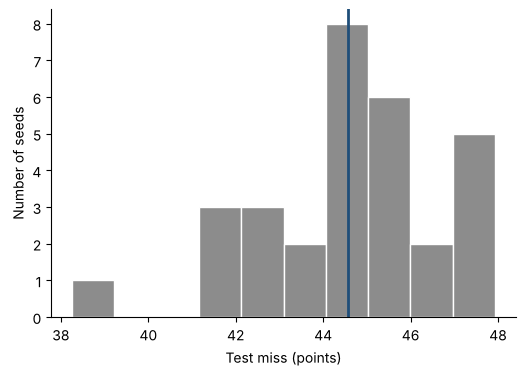

In [9]:
results = []
for seed in range(30):
    a, b, c, d = train_test_split(X, y, test_size=0.2, random_state=seed)
    results.append(miss(LinearRegression().fit(a, c), b, d))
plt.hist(results, bins=10, color=GRAY, edgecolor="white")
plt.axvline(np.mean(results), color=BLUE, linewidth=2)
plt.xlabel("Test miss (points)"); plt.ylabel("Number of seeds")
plt.show()

**Giải thích từng dòng**

- `results = []`: danh sách trống để cất 30 điểm thi.
- `for seed in range(30):`: `range(30)` cho các số từ 0 đến 29: mỗi số làm một hạt giống.
- `a, b, c, d = train_test_split(X, y, test_size=0.2, random_state=seed)`: chia sổ với hạt giống hiện tại. Ta đặt tên ngắn `a, b, c, d` cho bốn đầu ra (đề học, đề thi, đáp án học, đáp án thi) vì chỉ dùng ngay trong dòng sau.
- `results.append(miss(LinearRegression().fit(a, c), b, d))`: học trên tập học (`a`, `c`), chấm trên tập thi (`b`, `d`), thêm điểm vào danh sách.
- `plt.hist(results, bins=10, ...)`: (đã học ở chặng A3) histogram của 30 điểm.
- `plt.axvline(np.mean(results), color=BLUE, linewidth=2)`: `np.mean(...)` tính trung bình của danh sách; vạch xanh đánh dấu điểm trung bình.

**Cách đọc**

- **Con số:** 30 cách chia cho 30 điểm thi, từ khoảng **38** đến khoảng **48**, trung bình khoảng 45.
- **Bức tranh:** **cùng một máy, cùng một dữ liệu**, chỉ đổi cách chia mà điểm thi dao động cả 10 điểm. Điểm thi không phải một con số cố định, mà là *một lần rút thăm* từ một khoảng. Vì vậy, `42` không có gì thiêng liêng: nó chỉ là một trong nhiều cách chia hợp lệ.
- **Hệ quả thực tế:** khi so hai máy chênh nhau 2 đến 3 điểm, ta không thể kết luận máy nào tốt hơn, vì chênh lệch đó nhỏ hơn mức dao động do cách chia. Cách đúng hơn là kiểm định chéo (cross-validation), sẽ học ở phần D.

Còn tỉ lệ chia thì sao? Mình thử bốn mức `test_size` với 30 hạt giống mỗi mức.

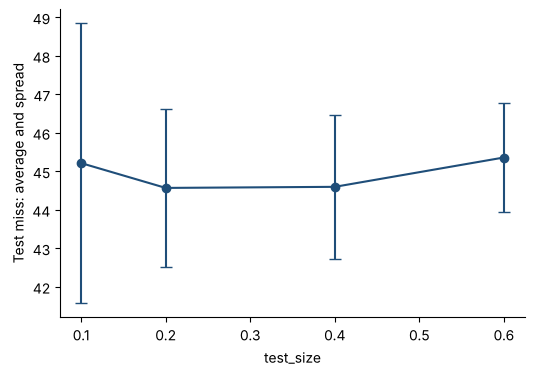

In [10]:
sizes = [0.1, 0.2, 0.4, 0.6]
means, spreads = [], []
for size in sizes:
    scores = []
    for seed in range(30):
        a, b, c, d = train_test_split(X, y, test_size=size, random_state=seed)
        scores.append(miss(LinearRegression().fit(a, c), b, d))
    means.append(np.mean(scores)); spreads.append(np.std(scores))
plt.errorbar(sizes, means, yerr=spreads, fmt="o-", color=BLUE, capsize=4)
plt.xlabel("test_size"); plt.ylabel("Test miss: average and spread")
plt.show()

**Giải thích từng dòng**

- `sizes = [0.1, 0.2, 0.4, 0.6]`: bốn tỉ lệ thi để thử: 10%, 20%, 40%, 60%.
- `means, spreads = [], []`: hai danh sách trống: một cho điểm trung bình, một cho độ dao động của từng tỉ lệ.
- `for size in sizes: ... for seed in range(30):`: **hai vòng lặp lồng nhau**: ngoài là tỉ lệ, trong là hạt giống. Với mỗi tỉ lệ, ta thử 30 hạt giống.
- `means.append(np.mean(scores)); spreads.append(np.std(scores))`: `np.std` tính **độ lệch chuẩn**: đo mức điểm dao động quanh trung bình (càng lớn càng dao động). Ta ghi lại cả trung bình lẫn độ dao động cho từng tỉ lệ.
- `plt.errorbar(sizes, means, yerr=spreads, fmt="o-", color=BLUE, capsize=4)`: `errorbar` vẽ **điểm kèm thanh sai số**: chấm là điểm trung bình, thanh dọc dài bằng độ dao động (`yerr`). `fmt="o-"` là kiểu vẽ chấm tròn nối bằng đường thẳng; `capsize=4` là độ rộng nắp hai đầu thanh.

**Cách đọc**

- **Con số:** điểm trung bình gần như không đổi (khoảng 45) ở mọi tỉ lệ, nhưng **thanh dao động thu hẹp** khi tập thi lớn hơn: từ khoảng 3,6 ở 10% xuống khoảng 1,4 ở 60%.
- **Bức tranh:** tập thi nhỏ giống như chỉ thi 4 câu: điểm may rủi nhiều. Tập thi lớn thì điểm ổn định hơn. Nhưng cái giá là tập học bé đi, máy có ít ví dụ hơn để học (ở 60% thi thì máy chỉ học trên 177 người).
- **Quy tắc thực hành:** 20% đến 30% là điểm cân bằng thường dùng. Dữ liệu càng ít thì càng cần kiểm định chéo thay vì chia một lần.

**Mang về chặng 3:** điểm thi chịu ảnh hưởng của cách chia (hạt giống, tỉ lệ). Một con số thi chỉ là một lần rút thăm. Đừng kết luận khi chênh lệch giữa hai máy nhỏ hơn mức dao động.

## Chặng 4: Nhìn trộm tập thi, cách tự lừa mình phổ biến nhất

**Câu hỏi:** nếu điểm thi dao động theo hạt giống, điều gì cám dỗ người ta *chọn hạt giống đẹp*?

Một kỹ sư muốn báo cáo thật đẹp có thể thử nhiều hạt giống và **chỉ báo cáo hạt giống cho điểm tốt nhất**.

In [11]:
print(f"Best seed reported : {min(results):.1f}")
print(f"Honest average     : {np.mean(results):.1f}")
print(f"Seeds that look better than the honest average: {sum(r < np.mean(results) for r in results)} of 30")

Best seed reported : 38.3
Honest average     : 44.6
Seeds that look better than the honest average: 14 of 30


**Giải thích từng dòng**

- `print(f"Best seed reported : {min(results):.1f}")`: `min(results)` lấy điểm thi **tốt nhất** (sai lệch nhỏ nhất) trong 30 lần. Đây là con số mà một người muốn "làm đẹp" sẽ báo cáo.
- `print(f"Honest average     : {np.mean(results):.1f}")`: điểm trung bình thật, đại diện cho khả năng thật của máy.
- `sum(r < np.mean(results) for r in results)`: `for r in results` duyệt từng điểm; `r < np.mean(results)` cho Đúng hoặc Sai; `sum` cộng lại (Đúng tính là 1), tức đếm có bao nhiêu hạt giống tốt hơn mức trung bình.

**Cách đọc**

- **Con số:** hạt giống tốt nhất báo khoảng **38**, trong khi mức thật là khoảng **45**. Chênh lệch khoảng 6 điểm chỉ do chọn lọc.
- **Bức tranh:** như thi 30 lần rồi chỉ khoe điểm cao nhất. Người nghe tưởng máy giỏi hơn thực tế, và ngoài đời máy sẽ "tụt" xuống mức 45. Việc này không cần gian dối rõ ràng, nó đến từ thói quen thử đi thử lại *trên tập thi* cho tới khi hài lòng. Mỗi lần ta chỉnh máy dựa theo điểm tập thi, tập thi lại "lọt" một chút vào quyết định của ta, nó dần thành tập học thứ hai.

**Quy tắc ba không để giữ tập thi trong sạch:**

1. **Không học** trên tập thi.
2. **Không chỉnh máy** theo điểm tập thi. Muốn chọn giữa nhiều cách, tách thêm một **tập kiểm tra** (validation) riêng (xem Tip pro).
3. **Không tính bất cứ thứ gì** từ tập thi để dùng cho máy (ví dụ điền ô trống bằng trung vị của cả bảng, chuẩn hóa bằng trung bình của cả bảng). Mọi con số như vậy phải tính từ tập học rồi áp sang tập thi.

**Mang về chặng 4:** tập thi chỉ dùng **một lần, ở cuối**. Chọn hạt giống đẹp hay chỉnh theo điểm thi đều làm điểm báo cáo lạc quan hơn thực tế.

## Phán quyết và bài học nghề

**Phán quyết.**

- **Con số:** chấm trên sổ cũ, cây quyết định đạt 0,0 và vượt xa máy tuyến tính (43). Chấm trên tập thi, cây lệch 57, tệ hơn máy tuyến tính 43. Với 10 suất, máy tuyến tính chọn đúng nhóm nặng (trung bình khoảng 256 trên mức trần 277), còn cây chọn nhóm chỉ khoảng 184.
- **Khuyến nghị:** dùng máy tuyến tính. Không dùng cây quyết định không giới hạn. Mọi báo cáo về máy phải kèm câu *"chấm trên tập thi bị giấu"*.

**Bài học nghề.**

1. **Điểm trên dữ liệu đã học là lời tự khai.** Chỉ điểm trên dữ liệu chưa từng thấy mới là bằng chứng.
2. **Hai điểm, một câu hỏi.** Luôn xem điểm học và điểm thi cạnh nhau. Học cao thi thấp là học vẹt; hai điểm gần nhau là yên tâm.
3. **Điểm thi là một lần rút thăm.** Đừng tranh cãi chênh lệch nhỏ hơn mức dao động.
4. **Giữ tập thi trong sạch.** Dùng một lần ở cuối.

**Một điều thành thật:** chia một lần như ở đây chỉ hợp khi dữ liệu đủ lớn. Với sổ nhỏ (vài trăm dòng như bài này), tập thi 89 người cho điểm khá ồn. Kiểm định chéo ở phần D sẽ giải quyết việc đó.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | Chấm máy trên dữ liệu nó đã học chỉ đo khả năng thuộc lòng. |
| 1 | `train_test_split` giấu một phần sổ làm tập thi. `test_size` là tỉ lệ giấu, `random_state` là hạt giống cho cách chia lặp lại được. |
| 2 | Điểm tập thi mới là điểm thật. Học cao thi thấp là học vẹt (quá khớp). |
| 3 | Điểm thi dao động theo hạt giống và tỉ lệ chia; đừng kết luận trên chênh lệch nhỏ. |
| 4 | Giữ tập thi trong sạch: dùng một lần, không chọn hạt giống đẹp, không chỉnh theo điểm thi. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Sổ cũ máy đọc để học | tập học (training set) | `X_train`, `y_train` |
| Đề thi giấu đi | tập thi (test set) | `X_test`, `y_test` |
| Bộ số cố định, đi đâu dùng cũng được | hạt giống ngẫu nhiên (random seed) | `random_state=42` |
| Phần trăm đề giấu đi | tỉ lệ tập thi | `test_size=0.2` |
| Học thuộc đáp án, không hiểu bài | quá khớp (overfitting) | cây không giới hạn độ sâu |
| Thi lại đúng đề đã làm | rò rỉ dữ liệu (data leakage) | chấm trên chính `X`, `y` đã học |
| Độ dao động của điểm thi | độ lệch chuẩn (standard deviation) | `np.std` |
| Đề luyện tập để chọn cách học | tập kiểm tra (validation set) | tách thêm lần nữa |

**Thử thách tự làm**

1. Đổi `random_state` ở chặng 1 từ 42 thành 7 và chạy lại chặng 2. Máy tuyến tính vẫn thắng cây quyết định chứ? Điểm thi thay đổi bao nhiêu? (Gợi ý: nhớ chạy lại các ô từ chặng 1 trở xuống.)
2. Giới hạn độ sâu của cây: đổi `DecisionTreeRegressor(random_state=0)` thành `DecisionTreeRegressor(max_depth=3, random_state=0)`. Điểm tập học và tập thi của cây thay đổi thế nào? (Gợi ý: cây nông hỏi ít câu nên khó thuộc lòng.)
3. Thử `test_size=0.9` (thi 90%, học 10%). Điều gì xảy ra với điểm của máy tuyến tính? Vì sao? (Gợi ý: máy chỉ học trên khoảng 44 người nhưng phải đoán cho 10 cột.)

**Checklist năng lực** (tự tick khi làm được)

- [ ] Giải thích được vì sao không được chấm máy trên dữ liệu nó đã học.
- [ ] Viết được `train_test_split` và nêu ý nghĩa `test_size`, `random_state`.
- [ ] Đọc được hai cột điểm học và điểm thi và nhận ra học vẹt.
- [ ] Giải thích được vì sao điểm thi dao động theo cách chia.
- [ ] Nêu được ba điều không được làm với tập thi.

## Phần thưởng (Tip pro): Ba tập: học, kiểm tra, thi


Khi cần chọn giữa nhiều cách (ví dụ nhiều giá trị cho một núm xoay), ta cần một **tập kiểm tra** để so sánh các cách đó, và giữ tập thi nguyên vẹn đến cuối cùng. Cách làm đơn giản nhất là chia hai lần:

- lần 1: tách 20% làm **tập thi**, cất kỹ;
- lần 2: từ phần còn lại, tách tiếp một phần làm **tập kiểm tra** (chọn cách, chỉnh núm);
- phần còn lại là **tập học**.

Chạy ô dưới để xem ba tập có kích thước thế nào.

In [12]:
X_rest, X_test3, y_rest, y_test3 = train_test_split(X, y, test_size=0.2, random_state=42)
X_train3, X_valid3, y_train3, y_valid3 = train_test_split(X_rest, y_rest, test_size=0.25, random_state=42)
print(len(X_train3), "train |", len(X_valid3), "validation |", len(X_test3), "test")

264 train | 89 validation | 89 test


**Giải thích từng dòng**

- `X_rest, X_test3, y_rest, y_test3 = train_test_split(X, y, test_size=0.2, random_state=42)`: lần chia thứ nhất: tách 20% làm tập thi (`X_test3`), phần còn lại (80%) đặt tên `X_rest`. Hậu tố `3` nhắc đây là bộ chia ba tập, khỏi nhầm với các biến ở trên.
- `X_train3, X_valid3, y_train3, y_valid3 = train_test_split(X_rest, y_rest, test_size=0.25, random_state=42)`: lần chia thứ hai, **chỉ trên phần còn lại**: tách 25% của 80% (tức 20% tổng) làm tập kiểm tra. Kết quả chia ba theo tỉ lệ 60% / 20% / 20%.
- `print(len(...), "train |", ...)`: in kích thước từng tập: 264, 89 và 89.